In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import solve_ivp, cumulative_trapezoid, quad, solve_bvp
from scipy.interpolate import CubicSpline
from numba import jit, njit, prange
plt.style.use("emilie_style.mplstyle")
colors = mpl.rcParams["axes.prop_cycle"].by_key()["color"]


In [ ]:
def feedback_potential(a, A0, epsilon):
    """Compute the feedback potential for a given activity level.

    Parameters
    ----------
    a : float
        The average activity level.
    A0 : float
        The maximum potential strength.
    epsilon : float
        The strength of the feedback.

    Returns
    -------
    float
        The feedback potential.
    """
    return A0 - epsilon * a

def simulate_mean_field_gillespie(initial_conditions, in_, out_, activate, deactivate, ts, tmax, n_particles=1000, rng=None):
    """Simulate the four-state system with the Gillespie algorithm.

    The potential strength us 

    The state vector is ordered as (t, p_in_A, p_in_N, p_out_A, p_out_N).
    The returned values are normalized by the total number of particles so
    downstream code can continue to interpret them as probabilities.
    """
    
    p_in_A, p_in_N, p_out_A, p_out_N = initial_conditions

    if rng is None:
        rng = np.random.default_rng()

    counts = np.array([p_in_A, p_in_N, p_out_A, p_out_N], dtype=float)
    total = counts.sum()
    if total <= 0:
        raise ValueError("initial_conditions must contain a positive total mass")

    counts = np.rint(counts / total * n_particles).astype(int) # Convert probabilities to integer counts
    counts[1] += n_particles - counts.sum() # Adjust the second compartment to ensure the total number of particles is correct

    save_times = np.arange(0.0, tmax + ts, ts)
    saved = np.zeros((len(save_times), 5))
    saved[0, :] = [0.0, *(counts / n_particles)]

    t = 0.0
    save_index = 1

    def record_until(current_time):
        nonlocal save_index
        while save_index < len(save_times) and current_time >= save_times[save_index]:
            saved[save_index, :] = [save_times[save_index], *(counts / n_particles)]
            save_index += 1

    record_until(t)

    while t < tmax and save_index < len(save_times):
        a1 = out_ * counts[0]
        a2 = out_ * counts[1]
        a3 = in_ * counts[2]
        a4 = in_ * counts[3]
        a5 = deactivate * counts[0]
        a6 = deactivate * counts[2]
        a7 = activate * counts[3]

        propensities = np.array([a1, a2, a3, a4, a5, a6, a7], dtype=float)
        a0 = propensities.sum()

        if a0 <= 0:
            break

        t += -np.log(rng.random()) / a0
        record_until(t)

        if t > tmax:
            break

        threshold = rng.random() * a0
        cumulative = 0.0

        if threshold < (cumulative := cumulative + a1):
            counts[0] -= 1
            counts[2] += 1
        elif threshold < (cumulative := cumulative + a2):
            counts[1] -= 1
            counts[3] += 1
        elif threshold < (cumulative := cumulative + a3):
            counts[2] -= 1
            counts[0] += 1
        elif threshold < (cumulative := cumulative + a4):
            counts[3] -= 1
            counts[1] += 1
        elif threshold < (cumulative := cumulative + a5):
            counts[0] -= 1
            counts[1] += 1
        elif threshold < (cumulative := cumulative + a6):
            counts[2] -= 1
            counts[3] += 1
        else:
            counts[3] -= 1
            counts[2] += 1

    while save_index < len(save_times):
        saved[save_index, :] = [save_times[save_index], *(counts / n_particles)]
        save_index += 1

    return saved

In [4]:
def p_out_definition(V_out, V_in, A):
    return V_out / (V_out + V_in * np.exp(A))

def permeability(D, delta, A0):
    return D / (delta * (1 + np.exp(A0)))

In [15]:
# System parameters
A0 = 5.0
b = 1000.0
D = 0.5
rf = 0.1 
rn = 0.5 
delta = rf
P = permeability(D, delta, A0)
print(f"Permeability P: {P}")

V_in = 4.0 / 3.0 * np.pi * rf**3
V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in
S = 4 * np.pi * rf**2

# Rates
out_rate = S * P / V_in
in_rate = S * P / V_out * np.exp(A0)
activation_rate = 1.0
deactivation_rate = 0.1
print(f"out_rate: {out_rate}, in_rate: {in_rate}, activation_rate: {activation_rate}, deactivation_rate: {deactivation_rate}")

# Initial conditions
p0_out = p_out_definition(V_out, V_in, A0)
p0_in = 1.0 - p0_out

p0_in_active, p0_out_active = 0.0, 0.0  # Assuming all molecules start in the neutral state
p0_in_neutral, p0_out_neutral = p0_in, p0_out

initial_conditions = (p0_in_active, p0_in_neutral, p0_out_active, p0_out_neutral)

Permeability P: 0.03346425462142428
out_rate: 1.0039276386427283, in_rate: 1.2015812287206231, activation_rate: 1.0, deactivation_rate: 0.1


In [16]:
tmax = 40 

# Simulate deterministic mean-field model
dt = 0.001  # Simulation parameters
ts = 0.01 

saved_euler = simulate_mean_field_euler(initial_conditions, in_rate, out_rate, activation_rate, deactivation_rate, dt, ts, tmax)


# Simulate the mean-field model using the Gillespie algorithm
n_particles = 200   # Simulation parameters
ts = 0.01 

saved_gillespie = simulate_mean_field_gillespie(initial_conditions, in_rate, out_rate, activation_rate, deactivation_rate, ts, tmax, n_particles, rng=None)

In [17]:
# Define the time array and the probabilities for the Euler method simulation

t_euler = saved_euler[:, 0]

p_in_A_euler = saved_euler[:, 1]    # Local probabilities
p_in_N_euler = saved_euler[:, 2]
p_out_A_euler = saved_euler[:, 3]
p_out_N_euler = saved_euler[:, 4]

p_in_euler = p_in_A_euler + p_in_N_euler    # Global probabilities
p_out_euler = p_out_A_euler + p_out_N_euler
p_A_euler = p_in_A_euler + p_out_A_euler
p_N_euler = p_in_N_euler + p_out_N_euler


# Define the time array and the probabilities for the Gillespie simulation
t_gillespie = saved_gillespie[:, 0]

p_in_A_gillespie = saved_gillespie[:, 1]
p_in_N_gillespie = saved_gillespie[:, 2]
p_out_A_gillespie = saved_gillespie[:, 3]
p_out_N_gillespie = saved_gillespie[:, 4]

p_in_gillespie = p_in_A_gillespie + p_in_N_gillespie
p_out_gillespie = p_out_A_gillespie + p_out_N_gillespie
p_A_gillespie = p_in_A_gillespie + p_out_A_gillespie
p_N_gillespie = p_in_N_gillespie + p_out_N_gillespie


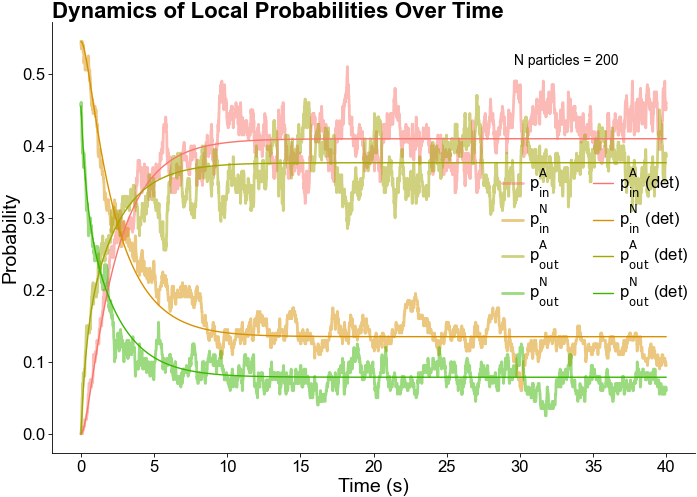

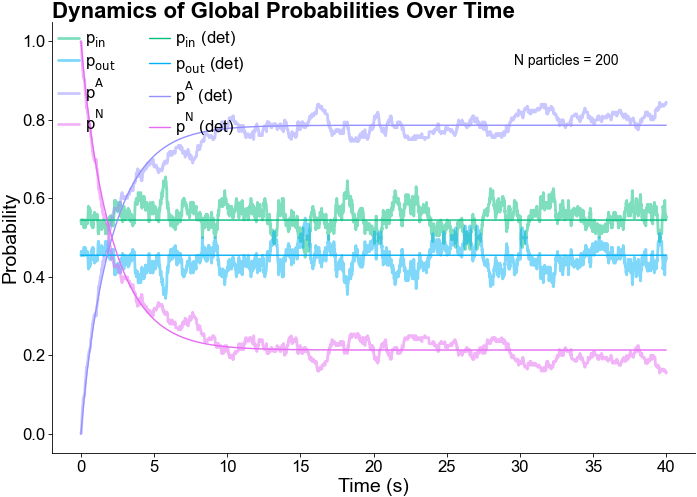

In [18]:
# Plotting the results
plt.figure()
plt.plot(t_gillespie, p_in_A_gillespie, alpha=0.5, label=r'$p_{\text{in}}^{\text{A}}$')
plt.plot(t_gillespie, p_in_N_gillespie, alpha=0.5, label=r'$p_{\text{in}}^{\text{N}}$')
plt.plot(t_gillespie, p_out_A_gillespie, alpha=0.5, label=r'$p_{\text{out}}^{\text{A}}$')
plt.plot(t_gillespie, p_out_N_gillespie, alpha=0.5, label=r'$p_{\text{out}}^{\text{N}}$')

plt.plot(t_euler, p_in_A_euler, color=colors[0], lw=1, label=r'$p_{\text{in}}^{\text{A}}$ (det)')
plt.plot(t_euler, p_in_N_euler, color=colors[1], lw=1, label=r'$p_{\text{in}}^{\text{N}}$ (det)')
plt.plot(t_euler, p_out_A_euler, color=colors[2], lw=1, label=r'$p_{\text{out}}^{\text{A}}$ (det)')
plt.plot(t_euler, p_out_N_euler, color=colors[3], lw=1, label=r'$p_{\text{out}}^{\text{N}}$ (det)')

plt.xlabel('Time (s)')
plt.ylabel('Probability')
plt.title('Dynamics of Local Probabilities Over Time')

plt.text(0.8, 0.9, f"N particles = {n_particles}", transform=plt.gca().transAxes, fontsize=10, ha='center')

plt.legend(ncol=2)
plt.show()


plt.figure()
plt.plot(t_gillespie, p_in_gillespie, alpha=0.5, label=r'$p_{\text{in}}$', color=colors[4])
plt.plot(t_gillespie, p_out_gillespie, alpha=0.5, label=r'$p_{\text{out}}$', color=colors[5])
plt.plot(t_gillespie, p_A_gillespie, alpha=0.5, label=r'$p^{\text{A}}$', color=colors[6])
plt.plot(t_gillespie, p_N_gillespie, alpha=0.5, label=r'$p^{\text{N}}$', color=colors[7])

plt.plot(t_euler, p_in_euler, color=colors[4], lw=1, label=r'$p_{\text{in}}$ (det)')
plt.plot(t_euler, p_out_euler, color=colors[5], lw=1, label=r'$p_{\text{out}}$ (det)')
plt.plot(t_euler, p_A_euler, color=colors[6], lw=1, label=r'$p^{\text{A}}$ (det)')
plt.plot(t_euler, p_N_euler, color=colors[7], lw=1, label=r'$p^{\text{N}}$ (det)')

plt.xlabel('Time (s)')
plt.ylabel('Probability')
plt.title('Dynamics of Global Probabilities Over Time')

plt.text(0.8, 0.9, f"N particles = {n_particles}", transform=plt.gca().transAxes, fontsize=10, ha='center')
plt.legend(ncol=2)
plt.show()


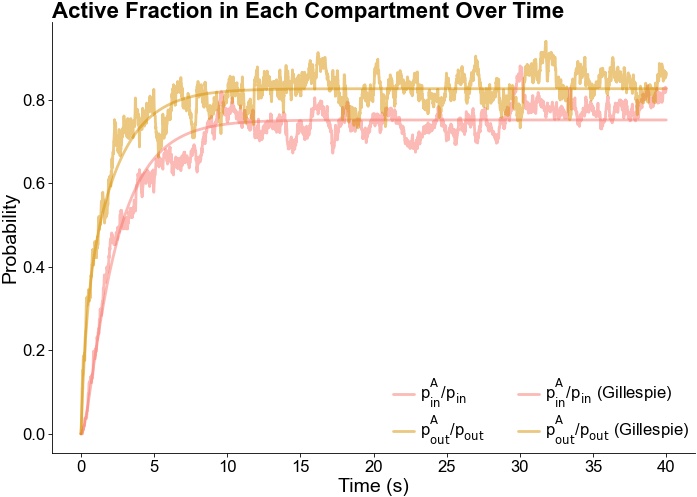

In [19]:
# Plot the active fraction in each compartment as a function of time

plt.figure()
plt.plot(t_euler, p_in_A_euler / p_in_euler, alpha=0.5, label=r'$p_{\text{in}}^{\text{A}} / p_{\text{in}}$', color=colors[0])
plt.plot(t_euler, p_out_A_euler / p_out_euler, alpha=0.5, label=r'$p_{\text{out}}^{\text{A}} / p_{\text{out}}$', color=colors[1])

plt.plot(t_gillespie, p_in_A_gillespie / p_in_gillespie, alpha=0.5, label=r'$p_{\text{in}}^{\text{A}} / p_{\text{in}}$ (Gillespie)', color=colors[0])
plt.plot(t_gillespie, p_out_A_gillespie / p_out_gillespie, alpha=0.5, label=r'$p_{\text{out}}^{\text{A}} / p_{\text{out}}$ (Gillespie)', color=colors[1])

plt.xlabel('Time (s)')
plt.ylabel('Probability')
plt.title('Active Fraction in Each Compartment Over Time')

plt.legend(ncol=2)
plt.show()

In [24]:
# Theoretical prediction 

def p_in_active_theoretical(p_out, in_rate, activate, deactivate):
    alpha = activate * in_rate
    beta = (activate + deactivate) * in_rate
    gamma = deactivate * (deactivate + activate + in_rate) 

    return alpha * p_out * (1 - p_out) / ((beta - gamma) * p_out + gamma), (alpha, beta, gamma)


def theoretical_optimal_A(activate, deactivate, rf, rn, D, delta=rf):
    """Calculate the theroretical optimal A for the given parameters."""
    C = 3 * D * rf**2 / (delta * (rn**3 - rf**3))

    V_in = 4.0 / 3.0 * np.pi * rf**3
    V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in
    
    N = (activate + deactivate) * V_out * (deactivate * V_in + C * V_out)
    D = deactivate * V_in**2 * (deactivate + activate + C)

    return 1 / 2 * np.log(N / D)

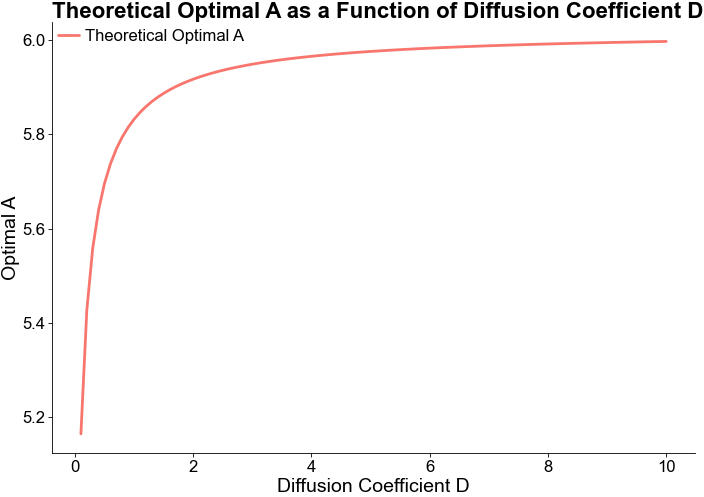

In [26]:
# Calculate the theoretical optimal A as a function of the diffusion coefficient D
D_values = np.linspace(0.1, 10, 100)
optimal_A_values = [theoretical_optimal_A(activation_rate, deactivation_rate, rf, rn, D_val) for D_val in D_values]

plt.figure()
plt.plot(D_values, optimal_A_values, label='Theoretical Optimal A', color=colors[0])
plt.xlabel('Diffusion Coefficient D')
plt.ylabel('Optimal A')
plt.title('Theoretical Optimal A as a Function of Diffusion Coefficient D')
plt.legend()

In [ ]:
# Simulate for different values of A0
A0_values = np.linspace(4, 8, 100)

p_in_active_final = []
p_in_neutral_final = []
p_out_active_final = []
p_out_neutral_final = []
in_rates = []
out_rates = []

for A0 in A0_values:

    p_o = p_out_definition(V_out, V_in, A0)
    p_i = 1.0 - p_o

    P = permeability(D, delta, A0)
    in_ = S * P / V_out * np.exp(A0)
    out_ = S * P / V_in
    in_rates.append(in_)
    out_rates.append(out_)

    # Initial conditions
    p_in_a = p_i * 0.5
    p_in_n = p_i * 0.5
    p_out_a = p_o * 0.5
    p_out_n = p_o * 0.5
    initial_conditions = (p_in_a, p_in_n, p_out_a, p_out_n)

    saved = simulate_mean_field(initial_conditions, in_, out_, activation_rate, deactivation_rate, dt, ts, tmax)

    # Store the final values of probabilities
    p_in_active_final.append(saved[-1, 1])
    p_in_neutral_final.append(saved[-1, 2])
    p_out_active_final.append(saved[-1, 3])
    p_out_neutral_final.append(saved[-1, 4])    

In [25]:
# Convert lists to numpy arrays for easier handling

p_out_total_final = np.array(p_out_active_final) + np.array(p_out_neutral_final)
p_in_total_final = np.array(p_in_active_final) + np.array(p_in_neutral_final)
p_active_total_final = np.array(p_in_active_final) + np.array(p_out_active_final)
p_neutral_total_final = np.array(p_in_neutral_final) + np.array(p_out_neutral_final)

# Find the optimal A0 that maximizes p_in_active_final
optimal_index = np.argmax(p_in_active_final)
optimal_A0 = A0_values[optimal_index]
print(f"The optimal A0 that maximizes p_in_active_final is: {optimal_A0}")

theoretical_optimal_A_value = theoretical_optimal_A(activation_rate, deactivation_rate, rf, rn, D, delta)
print(f"The theoretical optimal A0 is: {theoretical_optimal_A_value}")

The optimal A0 that maximizes p_in_active_final is: 5.818181818181818
The theoretical optimal A0 is: 5.832007451247925


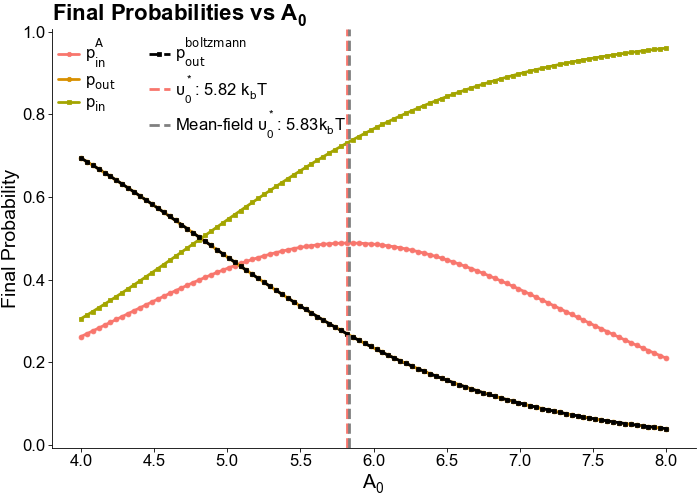

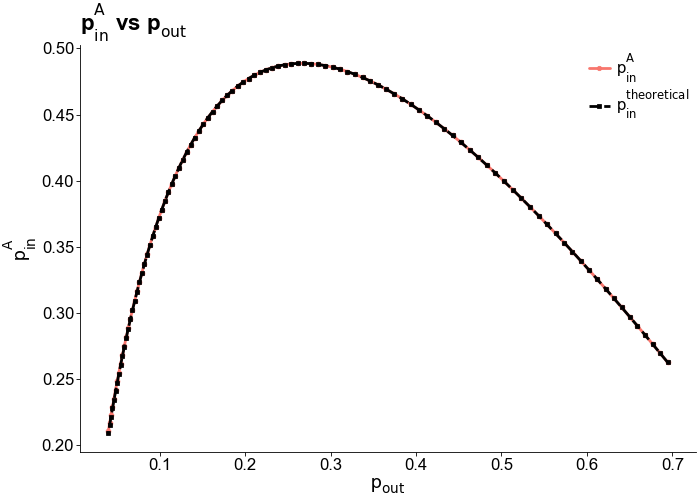

In [ ]:
# Plotting the results

plt.figure()
plt.plot(A0_values, p_in_active_final, label=r'$p_{\text{in}}^{\text{A}}$', marker='o')
plt.plot(A0_values, p_out_total_final, label=r'$p_{\text{out}}$', marker='o')
plt.plot(A0_values, p_in_total_final, label=r'$p_{\text{in}}$', marker='s')
plt.plot(A0_values, V_out * np.exp(-A0_values) / (V_in + V_out * np.exp(-A0_values)), label=r'$p_{\text{out}}^{\text{boltzmann}}$', marker='s', color='k', linestyle='--')
plt.axvline(x=optimal_A0, color=colors[0], linestyle='--', label=fr'$\upsilon^*_0$: {optimal_A0:.2f} $k_bT$')
plt.axvline(x=theoretical_optimal_A_value, color='grey', linestyle='--', label=fr'Mean-field $\upsilon^*_0$: {theoretical_optimal_A_value:.2f}$k_bT$')
plt.xlabel(r'$A_0$')
plt.ylabel('Final Probability')
plt.title('Final Probabilities vs $A_0$')
plt.legend(loc='best', ncol=2)
plt.show()

plt.figure()
theoretical_p_in_active, constants = p_in_active_theoretical(p_out_total_final, np.array(in_rates), activation_rate, deactivation_rate)
plt.plot(p_out_total_final, p_in_active_final, label=r'$p_{\text{in}}^{\text{A}}$', marker='o')
plt.plot(p_out_total_final, theoretical_p_in_active, label=r'$p_{\text{in}}^{\text{theoretical}}$', marker='s', color='k', linestyle='--')
plt.xlabel(r'$p_{\text{out}}$')
plt.ylabel(r'$p_{\text{in}}^{\text{A}}$')
plt.title(r'$p_{\text{in}}^{\text{A}}$ vs $p_{\text{out}}$')
plt.legend()
plt.show()

In [ ]:
def global_activity_old(a, activation_rate, deactivation_rate, rf, rn, A, epsilon=15):
    V_in = 4.0 / 3.0 * np.pi * rf**3
    V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in

    ratio = deactivation_rate / (activation_rate * V_out)
    exp = A - epsilon * a

    return 1.0 / (1.0 + ratio * (V_in * np.exp(exp) + V_out))


def global_activity(a, activation_rate, deactivation_rate, rf, rn, A, D, delta,epsilon=15):
    V_in = 4.0 / 3.0 * np.pi * rf**3
    V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in
    v = V_in / V_out

    S = 4 * np.pi * rf**2
    kappa_plus = S * D / (delta * V_out)
    kappa_minus = S * D / (delta * V_in)

    exp = A - epsilon * a
    w = np.exp(exp)

    a0 = deactivation_rate + kappa_minus
    a1 = deactivation_rate + kappa_plus
    b0 = (deactivation_rate + activation_rate) * a0
    b1 = deactivation_rate * (deactivation_rate + activation_rate + kappa_plus)

    return activation_rate * (a0 + a1*w) / ((1+v*w) * (b0 + b1*w))


def potential_at_fixed_points(a, activation_rate, deactivation_rate, rf, rn, A, D, delta,epsilon=15):
    exp = A - epsilon * a
    return exp + epsilon * global_activity(a, activation_rate, deactivation_rate, rf, rn, A, D, delta, epsilon)

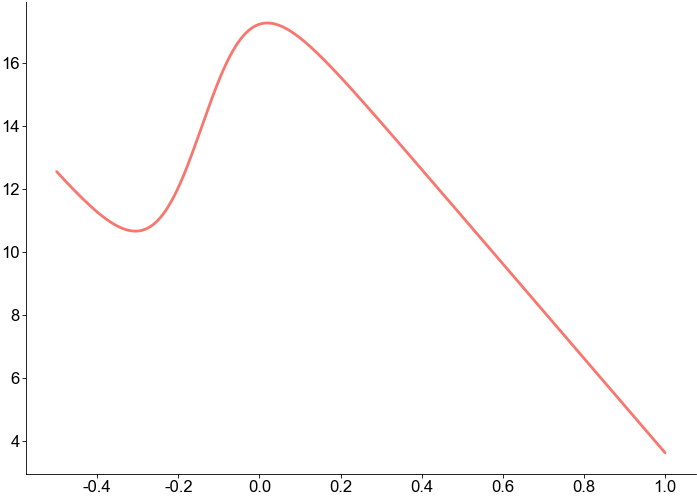

In [22]:
# Plot the potential at fixed points for a range of average activities
average_activity = np.linspace(-0.5, 1, 1000)

potential = potential_at_fixed_points(average_activity, activation_rate, deactivation_rate, rf, rn, A0, D, delta)

plt.figure()
plt.plot(average_activity, potential, label='Potential at Fixed Points')

In [32]:
average_activity = np.linspace(-0.5, 1, 1000) 

# System parameters
A0 = 9.0
b = 1000.0
D = 1.0
rf = 0.5
rn = 2.0
V_in = 4.0 / 3.0 * np.pi * rf**3
V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in
S = 4 * np.pi * rf**2

# Rates
delta = rf
P = permeability(D, delta, A0)
print(f"Permeability P: {P}")
out_rate = S * P / V_in
in_rate = S * P / V_out * np.exp(A0)
activation_rate = 1.0
deactivation_rate = 0.1
epsilon = 15
print(f"out_rate: {out_rate}, in_rate: {in_rate}, activation_rate: {activation_rate}, deactivation_rate: {deactivation_rate}")

global_a = global_activity(average_activity, activation_rate, deactivation_rate, rf, rn, A0, D, delta, epsilon)

upper_asymptote= 1 / (1 + deactivation_rate/activation_rate)

# Find fixed points where global_a intersects with average_activity
fixed_points = average_activity[np.isclose(global_a, average_activity, atol=1e-3)]
stability = []
for fp in fixed_points:
    derivative = (global_activity(fp + 1e-5, activation_rate, deactivation_rate, rf, rn, A0, D, delta, epsilon) - 
                  global_activity(fp - 1e-5, activation_rate, deactivation_rate, rf, rn, A0, D, delta, epsilon)) / (2 * 1e-5)
    stability.append('Stable' if derivative < 1 else 'Unstable')

print("Fixed Points and their Stability:")
for fp, stab in zip(fixed_points, stability):
    print(f"Fixed Point: {fp:.4f}, Stability: {stab}")

Permeability P: 0.00024678915197246345
out_rate: 0.0014807349118347807, in_rate: 0.1904526867474312, activation_rate: 1.0, deactivation_rate: 0.1
Fixed Points and their Stability:
Fixed Point: 0.0240, Stability: Stable
Fixed Point: 0.0255, Stability: Stable
Fixed Point: 0.1547, Stability: Unstable
Fixed Point: 0.1562, Stability: Unstable
Fixed Point: 0.9084, Stability: Stable
Fixed Point: 0.9099, Stability: Stable


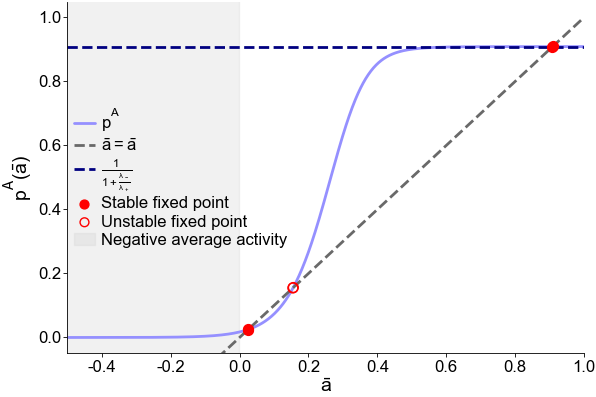

In [34]:
plt.figure(figsize=(6,4))

plt.plot(average_activity, global_a, label=r'$p^A$', color=colors[6])
plt.plot(average_activity, average_activity, color='dimgrey', linestyle='--', label=r'$\bar{a}=\bar{a}$')

plt.axhline(upper_asymptote, color='navy', linestyle='--', label=r'$\frac{1}{1 + \frac{\lambda_-}{\lambda_+}}$')
for fp, stab in zip(fixed_points, stability):
    if stab == 'Stable':
        plt.scatter(fp, fp, color='red', s=50, zorder=5, label=r'Stable fixed point' if 'Stable fixed point' not in plt.gca().get_legend_handles_labels()[1] else "")
    else:
        plt.scatter(fp, fp, facecolors='none', edgecolors='red', s=50, zorder=5, label=r'Unstable fixed point' if 'Unstable fixed point' not in plt.gca().get_legend_handles_labels()[1] else "")

plt.fill_between(average_activity, -0.2, 1.2, where=average_activity<0, color='lightgray', alpha=0.3, label=r'Negative average activity') 

plt.xlim(average_activity[0], average_activity[-1])
plt.ylim(-0.05, 1.05)

plt.xlabel(r'$\bar{a}$')
plt.ylabel(r'$p^A(\bar{a})$')
#plt.title('Global Activity Probability vs Average Activity')
plt.legend(loc='center left')

# Oscillatory activity 

Introducing a second species, z, which recovers A

In [35]:
def potential_two_species(A_0, epsilon, a_average, eta, z):
    return A_0 - epsilon * a_average + eta * z


def chi_param(in_rate, out_rate, deactivation_rate):
    return (out_rate + deactivation_rate) / (in_rate + out_rate + deactivation_rate)


def master_eq_average_activity(activation_rate, deactivation_rate, rf, rn, A_0, epsilon, a_average, eta, z):
    V_in = 4.0 / 3.0 * np.pi * rf**3
    V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in

    A = potential_two_species(A_0, epsilon, a_average, eta, z)
    p_out = p_out_definition(V_out, V_in, A)
    chi = chi_param(in_rate, out_rate, deactivation_rate)

    return activation_rate * (p_out - chi *a_average) - deactivation_rate * a_average


def master_eq_z(creation_rate, annihilation_rate, z, a_average):
    return creation_rate * a_average - annihilation_rate * z

In [48]:
# Simulate the dynamics of average activity and z over time

initial_a_average = 0.25
initial_z = 0.0
z_creation_rate = 0.5
z_annihilation_rate = 0.1
eta = 5.0
A0 = 5

# Define the time points for the simulation
t = np.linspace(0, 250, 1000)  # 1000 time points from 0 to 50

a_average_arr = np.zeros_like(t)
z_arr = np.zeros_like(t)

for i in range(len(t)):
    if i == 0:
        a_average_arr[i] = initial_a_average
        z_arr[i] = initial_z
    else:
        dt = t[i] - t[i-1]
        a_average_arr[i] = a_average_arr[i-1] + master_eq_average_activity(activation_rate, deactivation_rate, rf, rn, A0, epsilon, a_average_arr[i-1], eta, z_arr[i-1]) * dt
        z_arr[i] = z_arr[i-1] + master_eq_z(z_creation_rate, z_annihilation_rate, z_arr[i-1], a_average_arr[i-1]) * dt


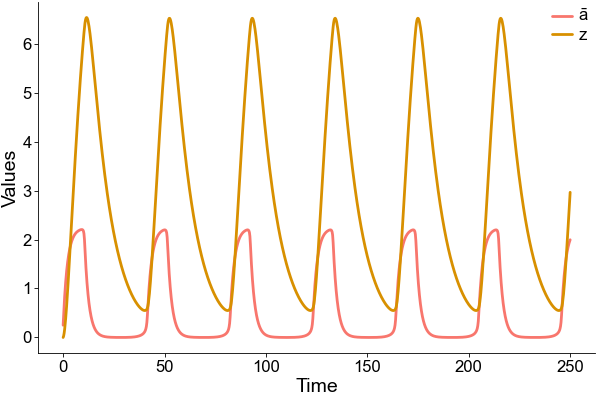

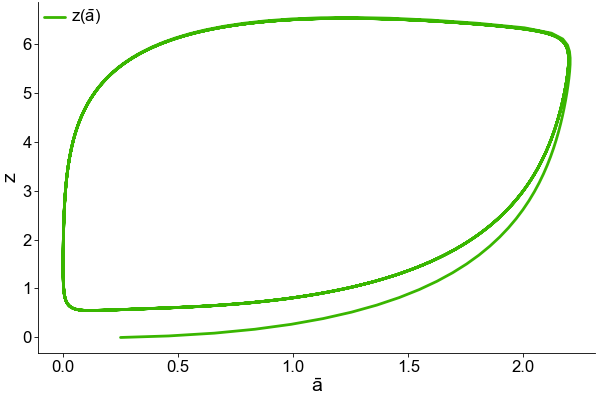

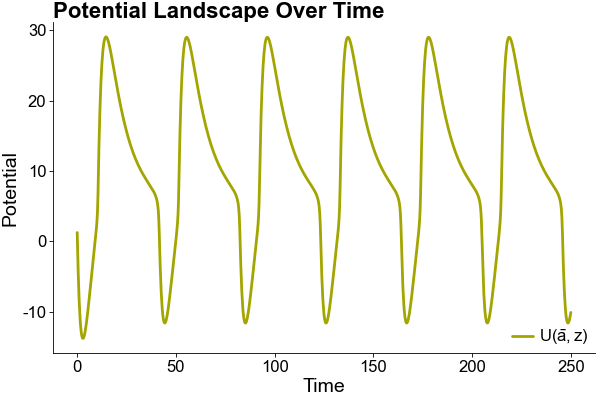

In [49]:
# Plot the average activity and z over time
plt.figure(figsize=(6,4))
plt.plot(t, a_average_arr, label=r'$\bar{a}$', color=colors[0])
plt.plot(t, z_arr, label=r'$z$', color=colors[1])
plt.legend()
plt.xlabel('Time')
plt.ylabel('Values')
plt.show()

plt.figure(figsize=(6,4))
plt.plot(a_average_arr, z_arr, label=r'$z(\bar{a})$', color=colors[3])
plt.legend()
plt.xlabel(r'$\bar{a}$')
plt.ylabel(r'$z$')
plt.show()

# Plot the potential landscape as a function of time 
pot = potential_two_species(A0, epsilon, a_average_arr, eta, z_arr)
plt.figure(figsize=(6,4))
plt.plot(t, pot, label=r'$U(\bar{a}, z)$', color=colors[2])
plt.xlabel('Time')
plt.ylabel('Potential')
plt.title('Potential Landscape Over Time')
plt.legend()

In [43]:
def z_nullcline(creation_rate, annihilation_rate, a_average):
    return (creation_rate / annihilation_rate) * a_average

def z_from_a_nullcline(a_average, activation_rate, deactivation_rate, rf, rn, A_0, epsilon, eta):
    V_in = 4.0 / 3.0 * np.pi * rf**3
    V_out = 4.0 / 3.0 * np.pi * rn**3 - V_in

    ratio = activation_rate / deactivation_rate
    potential = np.log(V_out / V_in * (ratio * (1 - a_average) / a_average) - 1)

    return 1 / eta * (potential - A_0 + epsilon * a_average)

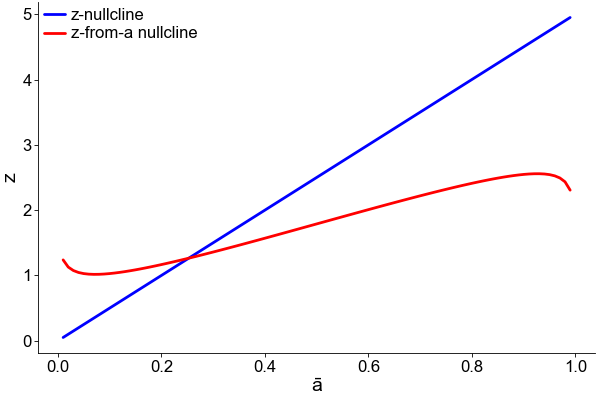

In [44]:
# Plot the nullclines in the a-z plane
a_values = np.linspace(0.01, 0.99, 100)
z_nullcline_values = z_nullcline(z_creation_rate, z_annihilation_rate, a_values)
z_from_a_nullcline_values = z_from_a_nullcline(a_values, activation_rate, deactivation_rate, rf, rn, A0, epsilon, eta)

plt.figure(figsize=(6,4))
plt.plot(a_values, z_nullcline_values, label='z-nullcline', color='blue')
plt.plot(a_values, z_from_a_nullcline_values, label='z-from-a nullcline', color='red')
plt.xlabel(r'$\bar{a}$')
plt.ylabel(r'$z$')
plt.legend()
plt.show()